# Traffic Signal Violation Detector - Phase 1

**Goal of this notebook:** prove that your environment and your video file both work,
before any AI code gets written.

Two things are checked here:

1. **Environment** - is PyTorch actually using your RTX 2050, or did it silently
   install the CPU-only build?
2. **Video** - can OpenCV decode your footage, and what are its resolution, FPS
   and frame count?

Run the cells top to bottom. Every cell is independent, so you can re-run any
single one after fixing something.

---

### Install first (in Anaconda Prompt or your terminal, not in the notebook)

Order matters. `ultralytics` and `easyocr` both depend on PyTorch, so if you let
them install it, pip grabs the CPU build and your GPU goes unused.

```
python -m venv venv
venv\Scripts\activate

pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126
pip install -r requirements.txt

python -m ipykernel install --user --name=traffic-detector
```

That last line registers this environment as a Jupyter kernel. After running it,
pick **traffic-detector** from the Kernel menu, otherwise the notebook runs on
your base Python and none of the packages will be found.

---
## Section 1 - Environment check

In [1]:
# -------------------------------------------------------------------
# CELL 1.1 - Python version
# -------------------------------------------------------------------
# The libraries used here need Python 3.9 or newer. 3.11 is the sweet
# spot: new enough for everything, old enough that every package has a
# prebuilt wheel (so pip does not try to compile anything).
# -------------------------------------------------------------------

import sys

version = f"{sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}"

print(f"Python version : {version}")
print(f"Running from   : {sys.executable}")   # confirms you are on the venv kernel

if sys.version_info >= (3, 9):
    print("\nStatus: OK")
else:
    print("\nStatus: TOO OLD - install Python 3.11")

Python version : 3.12.10
Running from   : c:\Users\Aditya\AppData\Local\Programs\Python\Python312\python.exe

Status: OK


In [2]:
# -------------------------------------------------------------------
# CELL 1.2 - OpenCV
# -------------------------------------------------------------------
# OpenCV handles all the video work in this project: opening the file,
# pulling out frames, drawing boxes, cropping number plates.
#
# Note the naming quirk - you install "opencv-python" but you import
# it as "cv2". That trips up almost everyone once.
# -------------------------------------------------------------------

import cv2

print(f"OpenCV version : {cv2.__version__}")
print("\nStatus: OK")

OpenCV version : 5.0.0

Status: OK


In [3]:
# -------------------------------------------------------------------
# CELL 1.3 - PyTorch and CUDA  <-- the cell that matters most
# -------------------------------------------------------------------
# torch.cuda.is_available() returns True only when BOTH are true:
#   - you installed the CUDA build of PyTorch (not the CPU build)
#   - your NVIDIA driver is working and recent enough
#
# If this prints False, everything will still run, just 10x slower on
# the CPU, with no error message to tell you why. That silent failure
# is exactly what this cell exists to catch.
# -------------------------------------------------------------------

import torch

print(f"PyTorch version : {torch.__version__}")

# The version string tells you which build you have.
# Ends in "+cpu"  -> CPU-only build, GPU will never be used
# Ends in "+cu126" (or similar) -> CUDA build, good
if "+cpu" in torch.__version__:
    print("WARNING: this is the CPU-only build of PyTorch")

CUDA_AVAILABLE = torch.cuda.is_available()

if CUDA_AVAILABLE:
    gpu_name = torch.cuda.get_device_name(0)                                # first GPU
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)  # bytes -> GB

    print(f"GPU             : {gpu_name}")
    print(f"VRAM            : {vram_gb:.1f} GB")

    # is_available() can return True while the driver is actually broken,
    # so run a real calculation on the GPU to be certain.
    test = torch.rand(1000, 1000, device="cuda")
    _ = test @ test                 # matrix multiply, executed on the GPU
    torch.cuda.synchronize()        # wait for the GPU to finish before moving on

    print("\nStatus: OK - GPU compute test passed")
else:
    print("\nStatus: FAILED - PyTorch cannot see your GPU")
    print("\nFix with:")
    print("  pip uninstall -y torch torchvision")
    print("  pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126")

# DEVICE is reused by every later cell and later notebook.
DEVICE = "cuda" if CUDA_AVAILABLE else "cpu"
print(f"\nDEVICE set to: {DEVICE}")

PyTorch version : 2.14.1+cpu

Status: FAILED - PyTorch cannot see your GPU

Fix with:
  pip uninstall -y torch torchvision
  pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126

DEVICE set to: cpu


In [4]:
# -------------------------------------------------------------------
# CELL 1.4 - YOLO (ultralytics)
# -------------------------------------------------------------------
# Ultralytics is the library that gives us YOLO. YOLO itself runs on
# PyTorch - that is where PyTorch does its real work in this project.
#
# The first run downloads yolov8s.pt (about 22 MB) into the current
# folder. Later runs load it from disk instantly.
#
# Why yolov8s and not yolov8n: your 4 GB of VRAM comfortably fits the
# "small" model, and it detects distant vehicles noticeably better
# than "nano". Avoid yolov8l / yolov8x - they fit, but leave no room
# for the OCR model to sit alongside.
# -------------------------------------------------------------------

# %pip install ultralytics
from ultralytics import YOLO
import ultralytics

print(f"Ultralytics version : {ultralytics.__version__}")
print("Loading yolov8s (first run downloads ~22 MB)...")

model = YOLO("yolov8s.pt")
model.to(DEVICE)          # move the model onto the GPU explicitly

print(f"\nStatus: OK - yolov8s loaded on {DEVICE}")

# The pretrained model knows 80 object classes from the COCO dataset.
# These four are the ones this project cares about. The numbers are
# the class IDs YOLO returns, which we filter on later.
VEHICLE_CLASSES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}
print(f"Vehicle classes we will keep: {VEHICLE_CLASSES}")

Ultralytics version : 8.4.184
Loading yolov8s (first run downloads ~22 MB)...

Status: OK - yolov8s loaded on cpu
Vehicle classes we will keep: {2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck'}


In [5]:
# -------------------------------------------------------------------
# CELL 1.5 - EasyOCR
# -------------------------------------------------------------------
# EasyOCR reads text out of an image. We point it at the cropped
# number plate later on. It also runs on PyTorch.
#
# Creating the Reader is slow (10-20 seconds) because it loads two
# neural networks, and the first run downloads roughly 100 MB.
#
# Important habit for later: create the Reader ONCE and reuse it.
# Creating it inside a frame loop would add 15 seconds per frame.
# -------------------------------------------------------------------
#%pip install easyocr
import easyocr

print("Loading EasyOCR models (first run downloads ~100 MB, be patient)...")

# ["en"] = English characters only, which is what Indian plates use.
# gpu=True pushes it onto CUDA alongside YOLO.
reader = easyocr.Reader(["en"], gpu=CUDA_AVAILABLE, verbose=False)

print(f"\nStatus: OK - EasyOCR loaded with gpu={CUDA_AVAILABLE}")

Loading EasyOCR models (first run downloads ~100 MB, be patient)...



Status: OK - EasyOCR loaded with gpu=False


c:\Users\Aditya\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(


In [6]:
# -------------------------------------------------------------------
# CELL 1.6 - VRAM check with both models loaded
# -------------------------------------------------------------------
# YOLO and EasyOCR are now both sitting in GPU memory. On a 4 GB card
# it is worth confirming how much room is left before adding the
# number plate detector in a later phase.
# -------------------------------------------------------------------

if CUDA_AVAILABLE:
    allocated = torch.cuda.memory_allocated(0) / (1024 ** 3)   # actually in use
    reserved = torch.cuda.memory_reserved(0) / (1024 ** 3)     # held by PyTorch's cache
    total = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)

    print(f"VRAM in use   : {allocated:.2f} GB")
    print(f"VRAM reserved : {reserved:.2f} GB")
    print(f"VRAM total    : {total:.2f} GB")
    print(f"Headroom      : {total - reserved:.2f} GB")
    print("\nIf headroom drops below about 1 GB in later phases, restart")
    print("the kernel - leftover tensors from earlier runs pile up.")
else:
    print("Running on CPU - no VRAM to report.")

Running on CPU - no VRAM to report.


---
## Section 2 - Video check

Set the path to your video below, then run the rest of the cells.

Why bother: some `.mp4` files use codecs OpenCV cannot decode. Finding that out
now is far better than discovering it halfway through the detection code, where
the failure looks like a bug in your own logic.

In [8]:
# -------------------------------------------------------------------
# CELL 2.1 - Set your video path
# -------------------------------------------------------------------
# Use a forward slash even on Windows - Python treats a backslash as
# an escape character, so "data\new\video.mp4" breaks in confusing
# ways. Forward slashes work fine on Windows.
# -------------------------------------------------------------------

VIDEO_PATH = r"C:\Users\Aditya\Documents\Aditya Pisal\AI\class_work\YOLO_project_virtual_line\CCTV_Footage.mp4"   # <-- change this

import os

if os.path.exists(VIDEO_PATH):
    size_mb = os.path.getsize(VIDEO_PATH) / (1024 ** 2)
    print(f"Found: {VIDEO_PATH}  ({size_mb:.1f} MB)")
else:
    print(f"NOT FOUND: {VIDEO_PATH}")
    print(f"\nYou are currently in: {os.getcwd()}")
    print("The path above is relative to that folder.")

Found: C:\Users\Aditya\Documents\Aditya Pisal\AI\class_work\YOLO_project_virtual_line\CCTV_Footage.mp4  (86.4 MB)


In [9]:
# -------------------------------------------------------------------
# CELL 2.2 - Open the video and read its properties
# -------------------------------------------------------------------
# VideoCapture is OpenCV's video reader. It does NOT raise an error
# for a bad file - it quietly returns an object that is not "opened".
# That is why isOpened() has to be checked by hand.
#
# Why each property matters later:
#   fps          -> converts a frame number into a real timestamp for
#                   the Excel report
#   width/height -> the coordinate space your stop line lives in
#   frame_count  -> lets you show progress while processing
# -------------------------------------------------------------------

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    print(f"ERROR: could not open '{VIDEO_PATH}'")
    print("\nPossible reasons:")
    print("  - wrong path (check cell 2.1)")
    print("  - a codec OpenCV cannot read")
    print("  - fix by re-encoding: ffmpeg -i input.mp4 -c:v libx264 output.mp4")
else:
    # cap.get() reads a property using a named constant, and always
    # returns a float - so convert the ones that should be integers.
    FPS = cap.get(cv2.CAP_PROP_FPS)
    WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    duration = FRAME_COUNT / FPS if FPS > 0 else 0   # guard against FPS of 0

    print(f"Resolution   : {WIDTH} x {HEIGHT}")
    print(f"Frame rate   : {FPS:.2f} FPS")
    print(f"Total frames : {FRAME_COUNT}")
    print(f"Duration     : {duration:.1f} seconds")

    # Worth knowing now rather than after writing the OCR code.
    if HEIGHT < 720:
        print("\nNOTE: below 720p. Number plate OCR will struggle badly.")
        print("      Use higher resolution footage if you can get it.")

Resolution   : 3840 x 2160
Frame rate   : 29.97 FPS
Total frames : 869
Duration     : 29.0 seconds


In [10]:
# -------------------------------------------------------------------
# CELL 2.3 - A helper to display frames inside the notebook
# -------------------------------------------------------------------
# In a .py script you would use cv2.imshow() to open a window. Inside
# Jupyter that freezes the kernel, so frames get drawn with matplotlib
# instead.
#
# The one gotcha that catches everybody: OpenCV stores colours as
# Blue-Green-Red, while matplotlib expects Red-Green-Blue. Skip the
# conversion and every image comes out looking blue. That is what
# cv2.cvtColor does below.
# -------------------------------------------------------------------

import matplotlib.pyplot as plt

def show_frame(frame, title="", size=(12, 7)):
    """Display one OpenCV frame inline in the notebook.

    Args:
        frame : the image, as a NumPy array in BGR colour order
        title : text shown above the image
        size  : figure size in inches, (width, height)
    """
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))   # BGR -> RGB
    plt.title(title)
    plt.axis("off")        # hide the pixel-coordinate axes
    plt.show()

print("show_frame() is ready.")

show_frame() is ready.


Frame shape: (2160, 3840, 3)  (height, width, colour channels)


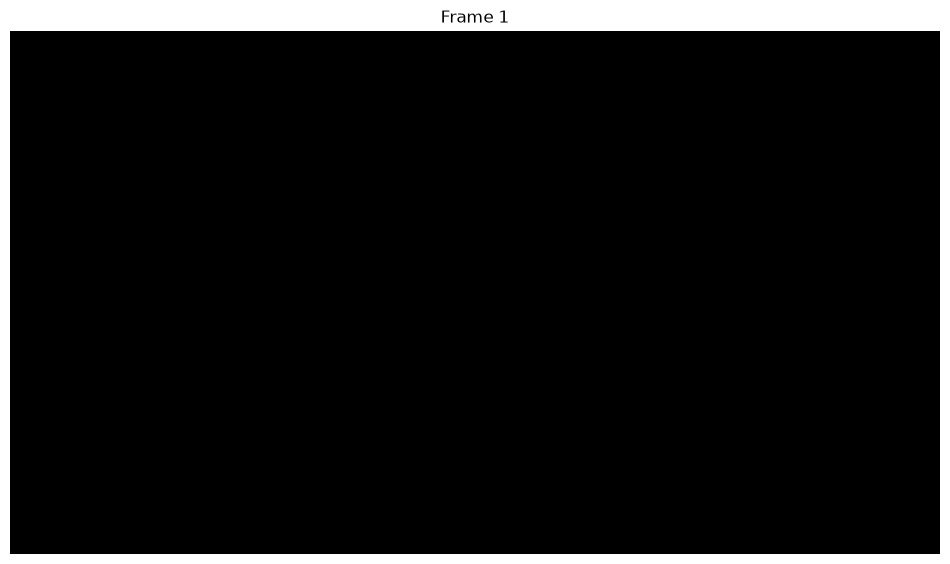

In [11]:
# -------------------------------------------------------------------
# CELL 2.4 - Read and display the first frame
# -------------------------------------------------------------------
# cap.read() returns two things:
#   success - False once the video has ended
#   frame   - the image, as a NumPy array shaped (height, width, 3)
#             where the 3 is Blue, Green, Red
# -------------------------------------------------------------------

# Rewind to the start, in case this cell is re-run after others have
# already advanced the position.
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

success, first_frame = cap.read()

if success:
    print(f"Frame shape: {first_frame.shape}  (height, width, colour channels)")
    show_frame(first_frame, "Frame 1")
else:
    print("Could not read a frame - re-run cell 2.2.")

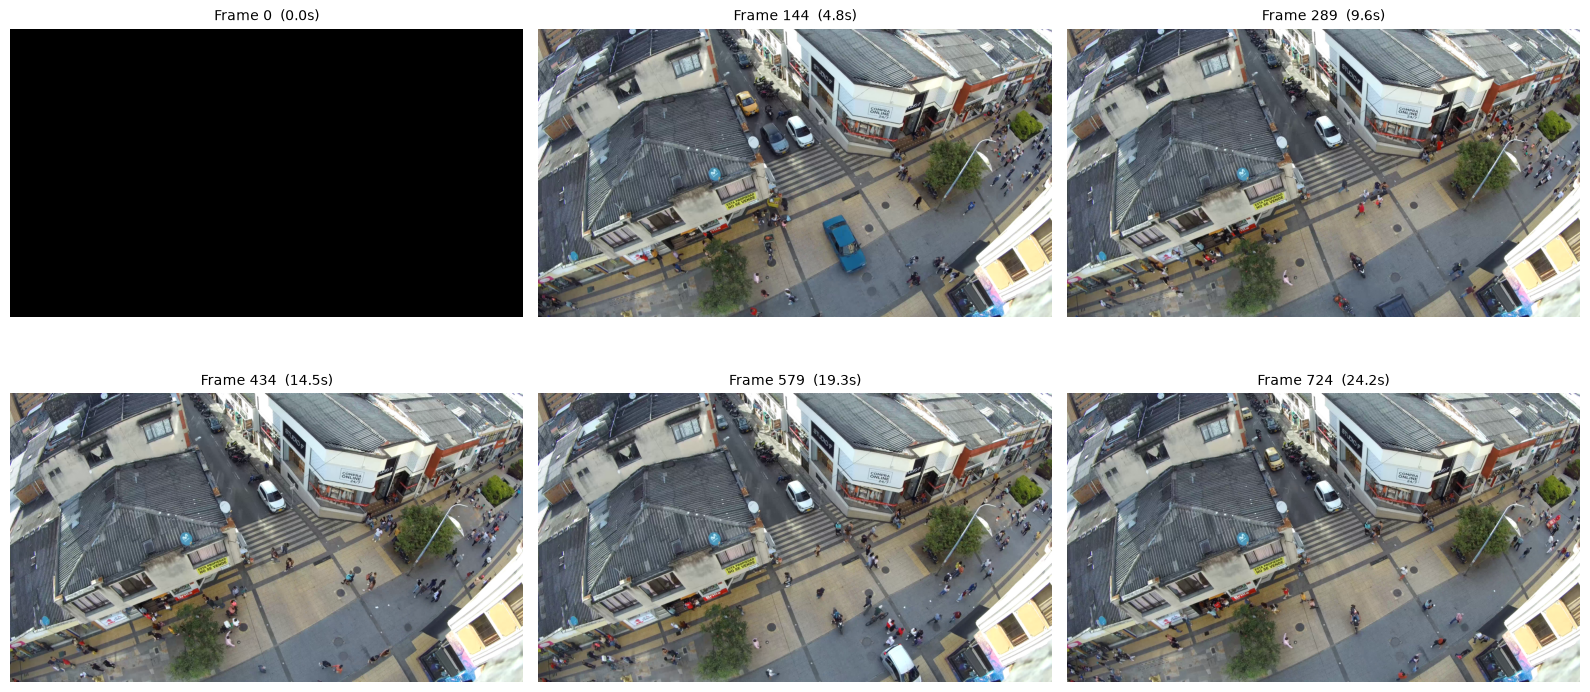

In [12]:
# -------------------------------------------------------------------
# CELL 2.5 - Sample frames from across the whole video
# -------------------------------------------------------------------
# Looking at six frames spread across the clip answers the questions
# that decide how the rest of the project is built:
#
#   - is the traffic light visible in every frame, and does it stay
#     in the same spot? (it must, for the signal ROI to work)
#   - does the camera move or zoom? (it must not)
#   - can you actually see the signal change from green to red?
#   - are number plates legible to your own eye?
# -------------------------------------------------------------------

SAMPLE_COUNT = 6

# Pick evenly spaced frame numbers across the video.
positions = [int(FRAME_COUNT * i / SAMPLE_COUNT) for i in range(SAMPLE_COUNT)]

# A 2-row by 3-column grid of images.
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, pos in zip(axes.flat, positions):
    # CAP_PROP_POS_FRAMES jumps straight to a given frame number
    # instead of reading through the file one frame at a time.
    cap.set(cv2.CAP_PROP_POS_FRAMES, pos)
    ok, frame = cap.read()

    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Frame {pos}  ({pos / FPS:.1f}s)", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

Saved output/reference_frame.jpg


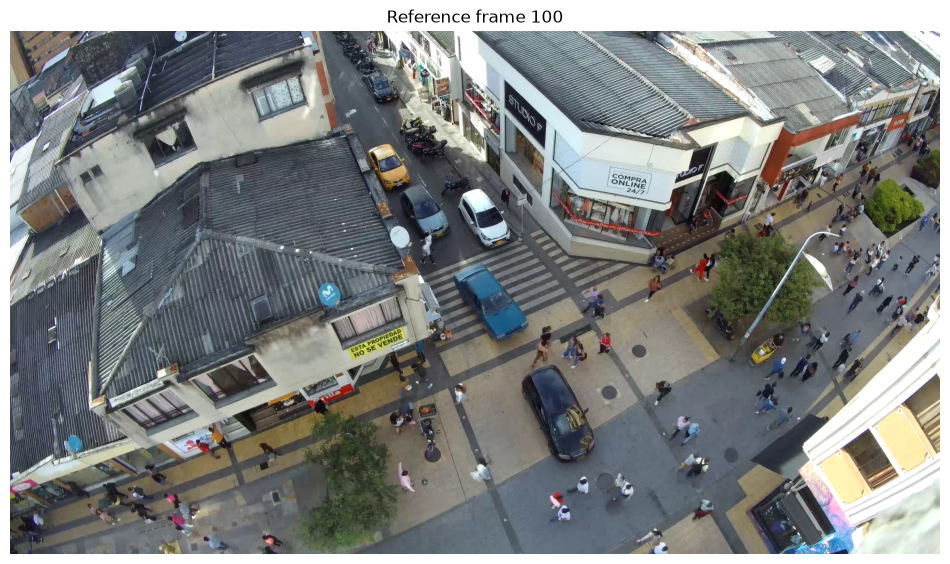

In [13]:
# -------------------------------------------------------------------
# CELL 2.6 - Save a reference frame for the next phase
# -------------------------------------------------------------------
# Phase 2 is the zone setup tool, where you click to mark your stop
# line and draw a box around the traffic light. That needs one clean
# still from this video.
#
# Pick a frame where the signal is clearly RED and at least one
# vehicle is waiting - it makes the marking much easier to judge.
# Change REFERENCE_FRAME based on what you saw in cell 2.5.
# -------------------------------------------------------------------

REFERENCE_FRAME = 100     # <-- change this

cap.set(cv2.CAP_PROP_POS_FRAMES, REFERENCE_FRAME)
ok, frame = cap.read()

if ok:
    os.makedirs("output", exist_ok=True)        # create the folder if missing
    out_path = "output/reference_frame.jpg"

    cv2.imwrite(out_path, frame)                # imwrite expects BGR, so no conversion
    print(f"Saved {out_path}")

    show_frame(frame, f"Reference frame {REFERENCE_FRAME}")
else:
    print(f"Frame {REFERENCE_FRAME} is out of range (video has {FRAME_COUNT} frames).")

In [14]:
# -------------------------------------------------------------------
# CELL 2.7 - Release the video file
# -------------------------------------------------------------------
# Always release when you are done. Leaving it open holds a lock on
# the file, which on Windows means you cannot move or delete it until
# the kernel restarts.
#
# Re-run cell 2.2 to open it again.
# -------------------------------------------------------------------

cap.release()
print("Video released.")

Video released.


---
## Phase 1 complete

What you should have confirmed by now:

- `DEVICE` prints `cuda`, and the GPU compute test passed
- YOLO and EasyOCR both loaded, with roughly 1.5 GB or more of VRAM still free
- Your video opens, and you know its resolution, FPS and frame count
- `output/reference_frame.jpg` exists and shows the signal on red

**Next - Phase 2: zone setup tool.** You click two points to mark the stop line
and drag a box around the traffic light. Those coordinates get saved to
`zones.json`, so the same code works on any video rather than being hardcoded to
this one camera angle.

A note on `cv2.imshow` in notebooks: Phase 2 needs real mouse clicks on an image,
which matplotlib cannot do cleanly inline. That one tool will be a `.py` script
run from the terminal, and the notebook will read the `zones.json` it produces.